# 11 · Benchmark inference serving

Which changes improve throughput without hurting the slowest requests?

Replay a fixed short and long request mix. Sweep batch and concurrency first. Compare the frozen model in a supported quantised format only after a correctness check. Profile each serving configuration before making runtime claims.

**Measures** — Time to first token, p95 total latency, requests per second, peak memory and quality drift.

**Evidence** — Load-test trace, comparable configuration records and a capacity envelope.

**Runtime** — One T4, serving compatibility profile. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 11

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


### Which dispatch should the Facilities Helpdesk use?

Open [Benchmark inference serving](https://docs.recohut.com/courses/advanced-ai-systems-engineering/4-operate-and-release/11-benchmark-inference-serving)
alongside the notebook. A request to classify the priority of fan F-250 arrives
with three others. Keep all four tickets, their order and the answer contract
fixed. Predict what changes when the dispatcher groups requests instead of
starting each alone.

The priority board and its answers are synthetic. It isolates serving
performance with known short and long inputs and a fixed token budget. This
workload does not use the registered release split or grade manual reading.

[NVIDIA benchmarking walkthrough](https://nvidia.github.io/TensorRT-LLM/developer-guide/perf-benchmarking.html)
· [MLPerf closed- and open-arrival scenarios](https://github.com/mlcommons/inference_policies/blob/master/inference_rules.adoc)

In [6]:
from dataclasses import asdict, dataclass
import gc
from time import perf_counter

import numpy as np


@dataclass(frozen=True)
class ServingRequest:
    request_id: str
    asset: str
    kind: str
    prompt: str
    expected: str


def serving_inputs(count):
    """Make a deterministic priority queue with a fixed short and long mix."""
    queue = []
    for i in range(count):
        long = i % 4 in (1, 2)
        asset = "F-250" if i == 1 else f"P-{i:03}"
        label = str(2 + i % 7)
        distractors = "\n".join(
            f"Asset F-{j:02} has priority 1; maintenance note archived."
            for j in range(22 if long else 1)
        )
        prompt = (
            f"{distractors}\nAsset {asset} has priority {label}. "
            f"What is the priority of {asset}? Reply only with the digit."
        )
        queue.append(ServingRequest(f"load-{i:03}", asset, "long" if long else "short", prompt, label))
    return queue


def waves(items, concurrency, batch_size):
    """Yield simultaneous arrivals, grouped into FIFO dispatches."""
    for offset in range(0, len(items), concurrency):
        wave = items[offset : offset + concurrency]
        yield [wave[i : i + batch_size] for i in range(0, len(wave), batch_size)]

### What does changing batch size leave fixed?

Four outstanding tickets can enter four dispatches of one or one dispatch
of four. The next group waits until the earlier group has finished. This
generates a closed-loop load with no HTTP traffic, streaming or continuous
batching. Its throughput depends on that arrival pattern.

In [7]:
CONFIGURATIONS = [(1, 1), (2, 1), (2, 2), (4, 1), (4, 4)]
REQUEST_COUNT = 100
DECODE_STEPS = 6
WARMUP_REQUESTS = 8
PROBE_COUNT = 12
TAIL_RESAMPLES = 1_500
TAIL_SEED = 11

serving_queue = serving_inputs(REQUEST_COUNT)
assert len({request.request_id for request in serving_queue}) == REQUEST_COUNT
assert sum(request.kind == "long" for request in serving_queue) == REQUEST_COUNT // 2
for concurrency, batch_size in CONFIGURATIONS:
    replay_order = [
        request
        for wave in waves(serving_queue, concurrency, batch_size)
        for group in wave
        for request in group
    ]
    assert replay_order == serving_queue
    print("Outstanding", concurrency, "batch cap", batch_size)

Outstanding 1 batch cap 1
Outstanding 2 batch cap 1
Outstanding 2 batch cap 2
Outstanding 4 batch cap 1
Outstanding 4 batch cap 4


### Where does F-250 wait?

Read the same four opening tickets in FIFO order. Until you see the measured
times, only the order and group boundaries are known.

In [8]:
opening = {
    "highlight_id": "load-001",
    "requests": [asdict(request) for request in serving_queue[:4]],
    "dispatches": [
        {
            "concurrency": 4,
            "batch_size": batch_size,
            "groups": [
                [request.request_id for request in batch]
                for batch in next(waves(serving_queue, 4, batch_size))
            ],
        }
        for batch_size in (1, 4)
    ],
}
assert opening["requests"][1]["asset"] == "F-250"
for plan in opening["dispatches"]:
    print("Opening dispatch", plan)

Opening dispatch {'concurrency': 4, 'batch_size': 1, 'groups': [['load-000'], ['load-001'], ['load-002'], ['load-003']]}
Opening dispatch {'concurrency': 4, 'batch_size': 4, 'groups': [['load-000', 'load-001', 'load-002', 'load-003']]}


### Where are the timing boundaries?

Time to first token begins at the wave's arrival and ends when the first
token IDs reach the host. Tokenisation, dispatch wait and prefill are inside
this interval. Total latency ends after the fixed continuation is decoded to
text in Python. There is no network or user-visible streaming in the timer.

Left padding puts the real final prompt token at the end of every row. Physical
cache positions include the padding. Rotary positions for the real tokens
count along each row's unpadded text.

In [9]:
def timed_decoder(model, tokenizer, requests, steps):
    import torch
    from transformers import DynamicCache

    device = model.device
    chats = [
        tokenizer.apply_chat_template(
            [{"role": "user", "content": request.prompt}],
            tokenize=False,
            add_generation_prompt=True,
        )
        for request in requests
    ]
    encoded = tokenizer(chats, return_tensors="pt", padding=True, add_special_tokens=False).to(device)
    input_ids = encoded.input_ids
    mask = encoded.attention_mask
    input_lengths = mask.sum(dim=1).tolist()
    padded_input_tokens = input_ids.shape[1]
    position_ids = (mask.cumsum(dim=1) - 1).clamp_min(0)
    cache_positions = torch.arange(padded_input_tokens, device=device)
    cache = DynamicCache()
    generated = []
    with torch.inference_mode():
        for index in range(steps):
            result = model(
                input_ids=input_ids,
                attention_mask=mask,
                position_ids=position_ids,
                cache_position=cache_positions,
                past_key_values=cache,
                use_cache=True,
                logits_to_keep=1,
            )
            cache = result.past_key_values
            token = result.logits[:, -1].argmax(dim=-1, keepdim=True)
            generated.append(token)
            if index == 0:
                first_ids = token.cpu()
                first_at = perf_counter()
            input_ids = token
            position_ids = mask.sum(dim=1, keepdim=True)
            mask = torch.cat([mask, mask.new_ones((mask.shape[0], 1))], dim=1)
            cache_positions = cache_positions[-1:] + 1
        generated_ids = torch.cat(generated, dim=1).cpu()
    outputs = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
    first_outputs = tokenizer.batch_decode(first_ids, skip_special_tokens=True)
    return {
        "first_at": first_at,
        "finished_at": perf_counter(),
        "inputs": input_lengths,
        "padded_input_tokens": padded_input_tokens,
        "first_outputs": first_outputs,
        "outputs": outputs,
        "token_ids": generated_ids,
        "encoded": encoded,
    }

### Does cached decoding preserve the first two tokens?

Check the first token against the library generator and replay the full prefix
to check the second. Then record the raw first token and expected digit. The
token parity check compares decoding implementations within one format. The
digit check asks a separate question about the response.

In [10]:
def correctness_probe(model, tokenizer, requests):
    import torch

    result = timed_decoder(model, tokenizer, requests, steps=2)
    encoded = result["encoded"]
    with torch.inference_mode():
        library_first = model.generate(
            **encoded, max_new_tokens=1, do_sample=False,
            temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id,
        )[:, -1:]
        assert torch.equal(library_first.cpu(), result["token_ids"][:, :1]), "First token diverged"
        ids = torch.cat([encoded.input_ids, library_first], dim=1)
        mask = encoded.attention_mask
        mask = torch.cat([mask, mask.new_ones((mask.shape[0], 1))], dim=1)
        raw = model(
            input_ids=ids, attention_mask=mask,
            position_ids=(mask.cumsum(dim=1) - 1).clamp_min(0),
            use_cache=False,
            logits_to_keep=1,
        ).logits[:, -1]
        uncached_second = raw.argmax(dim=-1).cpu()
    assert torch.equal(uncached_second, result["token_ids"][:, 1]), "Cached decode diverged"
    assert result["first_at"] <= result["finished_at"]
    return [
        {**asdict(request), "raw_first_token": text, "exact_first_token": text.strip() == request.expected}
        for request, text in zip(requests, result["first_outputs"])
    ]

### How do we count a failed request?

Record each accepted request exactly once. A failed request has a terminal
latency and no first-token observation. Keep it in total-latency percentiles
and the failure count, and exclude it from the completed-request numerator.

In [11]:
def replay(items, concurrency, batch_size, phase, decode, steps):
    records = []
    overall_start = perf_counter()
    for wave_index, wave in enumerate(waves(items, concurrency, batch_size)):
        accepted_at = perf_counter()
        for dispatch_index, batch in enumerate(wave):
            dispatch_at = perf_counter()
            queue_ms = 1e3 * (dispatch_at - accepted_at)
            common = dict(phase=phase, wave=wave_index, dispatch=dispatch_index,
                          actual_batch_size=len(batch), queue_ms=queue_ms)
            try:
                measured = decode(batch, steps)
            except (RuntimeError, ValueError) as exc:
                terminal_ms = 1e3 * (perf_counter() - accepted_at)
                records.extend(
                    dict(request_id=r.request_id, kind=r.kind, **common,
                         status=type(exc).__name__, ttft_ms=None, total_ms=terminal_ms,
                         input_tokens=None, padded_input_tokens=None, generated_tokens=0,
                         raw_first_token=None, raw_continuation=None, exact_first_token=False)
                    for r in batch
                )
                continue
            assert len(batch) == len(measured["outputs"]) == len(measured["inputs"]) == len(measured["first_outputs"])
            for request, size, first, text in zip(
                batch, measured["inputs"], measured["first_outputs"], measured["outputs"]
            ):
                records.append(dict(
                    request_id=request.request_id, kind=request.kind, **common, status="ok",
                    ttft_ms=1e3 * (measured["first_at"] - accepted_at),
                    total_ms=1e3 * (measured["finished_at"] - accepted_at),
                    input_tokens=size, padded_input_tokens=measured["padded_input_tokens"],
                    generated_tokens=steps, raw_first_token=first, raw_continuation=text,
                    exact_first_token=first.strip() == request.expected,
                ))
    return records, perf_counter() - overall_start


def percentile(rows, key, q):
    values = [r[key] for r in rows if r[key] is not None]
    return float(np.quantile(values, q)) if values else None


def summarize_replay(rows, elapsed, peak_mib):
    completed = sum(row["status"] == "ok" for row in rows)
    useful = sum(row["input_tokens"] or 0 for row in rows)
    allocated = sum(row["padded_input_tokens"] or 0 for row in rows)
    return dict(
        n=len(rows), completed=completed, failures=len(rows) - completed, elapsed_seconds=elapsed,
        p50_ttft_ms=percentile(rows, "ttft_ms", .50), p95_ttft_ms=percentile(rows, "ttft_ms", .95),
        p95_queue_ms=percentile(rows, "queue_ms", .95),
        p95_total_ms=percentile(rows, "total_ms", .95), throughput_rps=completed / elapsed,
        peak_mib=peak_mib, logical_prompt_tokens=useful, dense_prompt_positions=allocated,
        exact_first_tokens=sum(row["exact_first_token"] for row in rows),
    )


def paired_digits(baseline, candidate):
    assert [r["request_id"] for r in baseline] == [r["request_id"] for r in candidate]
    return dict(
        n=len(baseline),
        baseline_only=sum(a["exact_first_token"] and not b["exact_first_token"] for a, b in zip(baseline, candidate)),
        candidate_only=sum(b["exact_first_token"] and not a["exact_first_token"] for a, b in zip(baseline, candidate)),
        text_changes=sum(a["raw_first_token"] != b["raw_first_token"] for a, b in zip(baseline, candidate)),
    )


def paired_tail(baseline, candidate):
    """Keep requests sharing a wave together when resampling the p95 contrast."""
    assert [(r["request_id"], r["wave"]) for r in baseline] == [
        (r["request_id"], r["wave"]) for r in candidate
    ]
    groups = {}
    for first, second in zip(baseline, candidate):
        groups.setdefault(first["wave"], []).append([first["total_ms"], second["total_ms"]])
    waves_to_draw = [np.array(group) for group in groups.values()]

    def contrast(paired):
        base_p95, candidate_p95 = np.quantile(paired, .95, axis=0)
        return float(candidate_p95 - base_p95)

    rng = np.random.default_rng(TAIL_SEED)
    draws = [
        contrast(np.concatenate([waves_to_draw[index] for index in indices]))
        for indices in rng.integers(len(waves_to_draw), size=(TAIL_RESAMPLES, len(waves_to_draw)))
    ]
    low, high = np.quantile(draws, [.025, .975]).tolist()
    return dict(p95_total_delta_ms=contrast(np.concatenate(waves_to_draw)),
                p95_total_low_ms=low, p95_total_high_ms=high, paired_waves=len(waves_to_draw))

### How should we compare precision formats?

Replay the same queue in FP16 and in NF4 if the latter loads and passes the
parity probe on this runtime. NF4 changes weight storage; the matrix
computation uses FP16. Separate a load or parity failure from quality drift
on successful runs. The initial short replay follows the correctness probe
and may reuse kernels, so it is not a cold-start measurement.

[Transformers cache documentation](https://huggingface.co/docs/transformers/v4.51.3/cache_explanation)
· [bitsandbytes quantisation](https://huggingface.co/docs/transformers/v4.51.3/quantization/bitsandbytes)

In [12]:
def run_serving():
    import torch

    assert "T4" in device_name(), "Run the capacity experiment on a Colab T4"
    probe_queue = [
        *serving_queue[:4],
        *[
            ServingRequest(
                f"probe-{i:02}", f"PT-{i}", "short",
                f"Equipment PT-{i} is in zone {i % 7 + 2}. Reply with only its zone digit.",
                str(i % 7 + 2),
            )
            for i in range(PROBE_COUNT - 4)
        ],
    ]
    formats = {}
    summaries = []
    traces = []
    slices = []
    probes = []
    schedule_pairs = []
    for format_name in ("fp16", "nf4"):
        start_load = perf_counter()
        try:
            tokenizer, model = load_text(quant=(format_name == "nf4"))
            tokenizer.padding_side = "left"
            sync()
            load_ms = 1e3 * (perf_counter() - start_load)
        except (ImportError, RuntimeError, ValueError) as exc:
            if format_name == "fp16":
                raise
            formats[format_name] = dict(status="load_failed", error_type=type(exc).__name__)
            print("NF4_LOAD_FAILED", type(exc).__name__, str(exc))
            break
        try:
            quality = [
                outcome for group in waves(probe_queue, 4, 4)
                for outcome in correctness_probe(model, tokenizer, group[0])
            ]
        except (RuntimeError, ValueError, AssertionError) as exc:
            if format_name == "fp16":
                raise
            formats[format_name] = dict(status="parity_failed", load_ms=load_ms, error_type=type(exc).__name__)
            print("NF4_PARITY_FAILED", type(exc).__name__, str(exc))
            del model, tokenizer
            gc.collect()
            torch.cuda.empty_cache()
            break
        formats[format_name] = dict(status="ok", load_ms=load_ms, probe_n=len(quality),
                                    probe_exact=sum(row["exact_first_token"] for row in quality))
        probes.extend({**row, "format": format_name} for row in quality)

        def decode(batch, steps):
            return timed_decoder(model, tokenizer, batch, steps)

        warm_results = {}
        for concurrency, batch_size in CONFIGURATIONS:
            labels = dict(format=format_name, concurrency=concurrency, batch_size=batch_size)
            for phase, items in (
                ("prewarm", serving_queue[:concurrency]),
                ("warmup", serving_queue[:WARMUP_REQUESTS]),
                ("warm", serving_queue),
            ):
                torch.cuda.reset_peak_memory_stats(model.device)
                rows, duration = replay(items, concurrency, batch_size, phase, decode, DECODE_STEPS)
                peak_mib = torch.cuda.max_memory_allocated(model.device) / 2**20
                if phase == "warmup":
                    continue
                assert [row["request_id"] for row in rows] == [request.request_id for request in items]
                traces.extend({**row, **labels} for row in rows)
                summaries.append({**labels, "phase": phase, **summarize_replay(rows, duration, peak_mib)})
                if phase == "warm":
                    warm_results[(concurrency, batch_size)] = rows
                    for kind in ("short", "long"):
                        group = [row for row in rows if row["kind"] == kind]
                        slices.append({**labels, "kind": kind, "n": len(group),
                                       "p95_total_ms": percentile(group, "total_ms", .95),
                                       "p95_ttft_ms": percentile(group, "ttft_ms", .95)})
        schedule_pairs.extend(
            dict(format=format_name, concurrency=concurrency, baseline_batch=1, candidate_batch=concurrency,
                 **paired_digits(warm_results[(concurrency, 1)], warm_results[(concurrency, concurrency)]),
                 **paired_tail(warm_results[(concurrency, 1)], warm_results[(concurrency, concurrency)]))
            for concurrency in (2, 4)
        )
        del model, tokenizer
        gc.collect()
        torch.cuda.empty_cache()
    format_pair = None
    if formats["nf4"]["status"] == "ok":
        format_pair = paired_digits(
            [r for r in probes if r["format"] == "fp16"], [r for r in probes if r["format"] == "nf4"]
        )
    return formats, summaries, traces, slices, probes, schedule_pairs, format_pair

### What should we repeat before capacity planning?

Compare throughput and tail latency on the same request mix, then inspect
short and long requests separately. Peak allocated memory includes the weights
and live tensors that PyTorch tracks. It excludes CUDA memory outside the
allocator. A single replay gives a conditional profile of this queue.
The separate probe checks exact digits under greedy decoding and does not
estimate Facilities Helpdesk quality on the release split.

[PagedAttention](https://arxiv.org/html/2309.06180v1)
· [DistServe](https://www.usenix.org/system/files/osdi24-zhong-yinmin.pdf)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Format readiness: {'fp16': {'status': 'ok', 'load_ms': 17338.68321799946, 'probe_n': 12, 'probe_exact': 12}, 'nf4': {'status': 'ok', 'load_ms': 12318.11757200012, 'probe_n': 12, 'probe_exact': 12}}
Measured lab body, seconds: 319.479
Profile: {'format': 'fp16', 'concurrency': 1, 'batch_size': 1, 'phase': 'prewarm', 'n': 1, 'completed': 1, 'failures': 0, 'elapsed_seconds': 0.3501357019995339, 'p50_ttft_ms': 56.329650999941805, 'p95_ttft_ms': 56.329650999941805, 'p95_queue_ms': 0.0004889998308499344, 'p95_total_ms': 350.0084199995399, 'throughput_rps': 2.8560355150567625, 'peak_mib': 2959.748046875, 'logical_prompt_tokens': 71, 'dense_prompt_positions': 71, 'exact_first_tokens': 1}
Profile: {'format': 'fp16', 'concurrency': 1, 'batch_size': 1, 'phase': 'warm', 'n': 100, 'completed': 100, 'failures': 0, 'elapsed_seconds': 22.764974201999394, 'p50_ttft_ms': 47.78450599997086, 'p95_ttft_ms': 58.29298694961835, 'p95_queue_ms': 0.0013691000731341774, 'p95_total_ms': 321.2909792496248, 'throug

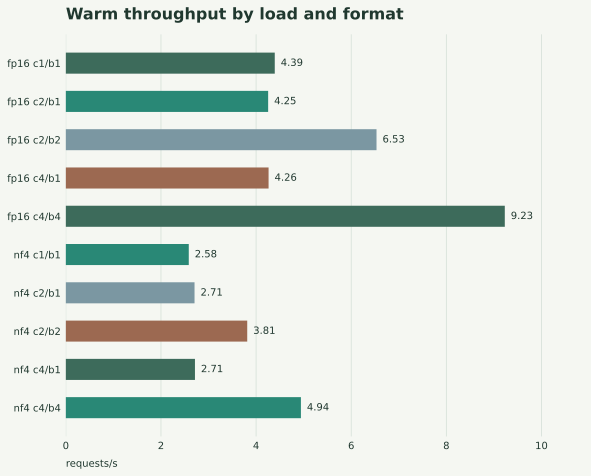

In [13]:
if COURSE_SMOKE:
    def fixture_decode(batch, steps):
        if len(batch) == 1 and batch[0].request_id == "load-002":
            raise RuntimeError("fixture terminal failure")
        now = perf_counter()
        sizes = [4 if request.kind == "short" else 12 for request in batch]
        outputs = [request.expected for request in batch]
        return dict(first_at=now, finished_at=now, inputs=sizes, padded_input_tokens=max(sizes),
                    first_outputs=outputs, outputs=outputs)

    serial, duration = replay(serving_queue[:4], 4, 1, "fixture", fixture_decode, DECODE_STEPS)
    grouped, _ = replay(serving_queue[:4], 4, 4, "fixture", fixture_decode, DECODE_STEPS)
    assert summarize_replay(serial, duration, 0)["failures"] == 1
    assert serial[2]["ttft_ms"] is None and serial[2]["total_ms"] >= serial[2]["queue_ms"]
    assert [row["dispatch"] for row in serial] == [0, 1, 2, 3]
    assert {row["dispatch"] for row in grouped} == {0}
    assert paired_digits(serial, grouped)["candidate_only"] == 1
    same = paired_tail(serial, serial)
    assert same == dict(p95_total_delta_ms=0.0, p95_total_low_ms=0.0, p95_total_high_ms=0.0, paired_waves=1)
    save("summary", {"mode": "fixture", "measured_gpu": False})
    save("records", {"mode": "fixture", "opening": opening})
    print("SMOKE OK")
else:
    started = perf_counter()
    formats, profiles, trace, slices, probes, schedule_pairs, format_pair = run_serving()
    elapsed = perf_counter() - started
    print("Format readiness:", formats)
    print("Measured lab body, seconds:", round(elapsed, 3))
    for row in profiles:
        print("Profile:", row)
    print("Queue schedule digit pairs:", schedule_pairs, "Format probe pair:", format_pair)
    opening_trace = [r for r in trace if r["request_id"] == opening["highlight_id"]
                     and r["phase"] == "warm" and r["concurrency"] == 4]
    print("F-250 measured examples:", opening_trace)
    save("summary", {
        "mode": "measured", "request_count": REQUEST_COUNT, "decode_steps": DECODE_STEPS,
        "warmup_requests": WARMUP_REQUESTS, "measurement_wall_seconds": elapsed,
        "tail_resamples": TAIL_RESAMPLES, "tail_seed": TAIL_SEED,
        "formats": formats, "profiles": profiles, "length_slices": slices,
        "schedule_pairs": schedule_pairs, "format_pair": format_pair,
    })
    save("records", {
        "opening": opening, "requests": [asdict(r) for r in serving_queue],
        "traces": trace, "format_probe": probes,
    })
    warm_profiles = [row for row in profiles if row["phase"] == "warm"]
    labels = [f'{r["format"]} c{r["concurrency"]}/b{r["batch_size"]}' for r in warm_profiles]
    chart("Warm throughput by load and format", labels,
          [r["throughput_rps"] for r in warm_profiles], "requests/s")

### Read the result

Pick a precision and batch cap for a latency target. Find the F-250 trace
under both dispatch schedules. Explain whether waiting behind other work or
forming a longer padded batch explains its first-token time. Carry any
disagreement between formats to release evaluation before changing precision.

Return to [Benchmark inference serving](https://docs.recohut.com/courses/advanced-ai-systems-engineering/4-operate-and-release/11-benchmark-inference-serving).

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration](https://arxiv.org/abs/2306.00978)
- [Efficient Memory Management for Large Language Model Serving with PagedAttention](https://arxiv.org/abs/2309.06180)